# Comparação de modelos: Regressão Logística, Random Forest, XGBoost e LightGBM

Extensão do notebook [`Analise_Fraude_Cartao.ipynb`](Analise_Fraude_Cartao.ipynb). O objetivo é comparar **quatro modelos** com **o mesmo protocolo** do projeto original, para que os números sejam diretamente comparáveis:

- mesma base (`data/creditcard.csv`, 284.807 transações, 492 fraudes) e as mesmas 30 colunas de entrada (`Time`, `V1`–`V28`, `Amount`);
- mesma **partição temporal 70/15/15 por `Time`** (treino 199.368 / validação 42.718 / teste 42.721);
- `StandardScaler` ajustado **só no treino** (usado apenas na regressão logística); **sem reamostragem**; desbalanceamento tratado com pesos de classe (`class_weight` / `scale_pos_weight`);
- **busca aleatória curta de hiperparâmetros** com validação cruzada estratificada (3 dobras) **somente no treino**, otimizando Average Precision;
- **seleção do modelo pela Average Precision (PR-AUC) na validação**;
- **limiar escolhido na validação** e **uma única avaliação no teste**.

In [1]:
# Ferramentas: tabelas, contas, gráficos, modelos e métricas.
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import loguniform, randint, uniform
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
    fbeta_score, precision_recall_curve, precision_score, recall_score, roc_auc_score)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Mesma semente do notebook original: resultados repetíveis.
SEED = 42
ARQUIVO = Path("data/creditcard.csv")
PASTA_RELATORIOS = Path("reports")
PASTA_RELATORIOS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["savefig.dpi"] = 160

## 1. Dados e partição temporal (idêntica ao notebook original)

In [2]:
# Lê a base e confere tamanho e quantidade de fraudes.
df = pd.read_csv(ARQUIVO)
ALVO = "Class"
print(f"{len(df):,} linhas × {len(df.columns)} colunas | fraudes: {int(df[ALVO].sum())} ({df[ALVO].mean():.3%})")
assert len(df) == 284_807 and int(df[ALVO].sum()) == 492

# Mesmo corte do notebook original: ~70% / ~85% acumulados por instante de Time.
contagens_tempo = df.groupby("Time", sort=True).size(); acum = contagens_tempo.cumsum()
t70 = acum.index[np.searchsorted(acum.to_numpy(), .70*len(df), side="left")]
t85 = acum.index[np.searchsorted(acum.to_numpy(), .85*len(df), side="left")]
treino = df[df.Time <= t70].copy()
valid = df[(df.Time > t70) & (df.Time <= t85)].copy()
teste = df[df.Time > t85].copy()
assert treino.Time.max() < valid.Time.min() < teste.Time.min()

Xtr, ytr = treino.drop(columns=ALVO), treino[ALVO]
Xv, yv = valid.drop(columns=ALVO), valid[ALVO]
Xt, yt = teste.drop(columns=ALVO), teste[ALVO]
display(pd.DataFrame({"linhas": [len(treino), len(valid), len(teste)],
    "fraudes": [ytr.sum(), yv.sum(), yt.sum()]}, index=["Treino", "Validação", "Teste"]))

# Razão legítimas/fraudes no treino: usada como peso da classe rara no XGBoost e no LightGBM.
razao = float((ytr == 0).sum() / ytr.sum())
print(f"Legítimas por fraude no treino: {razao:.1f}")

284,807 linhas × 31 colunas | fraudes: 492 (0.173%)


,linhas,fraudes
Treino,199368,384
Validação,42718,56
Teste,42721,52


Legítimas por fraude no treino: 518.2


## 2. Referência: reprodução dos modelos originais

Mesmas configurações do notebook original (sem busca de hiperparâmetros), para confirmar que o protocolo foi reproduzido.

In [3]:
def limiar_f2(y, prob):
    """Limiar que maximiza F2 (mesma regra do notebook original)."""
    p, r, t = precision_recall_curve(y, prob)
    f2 = 5 * p[:-1] * r[:-1] / (4 * p[:-1] + r[:-1] + 1e-12)
    return float(t[int(np.nanargmax(f2))])

def limiar_precisao_com_recall(y, prob, recall_min=0.80):
    """Limiar de maior precisão entre os que mantêm recall >= recall_min."""
    p, r, t = precision_recall_curve(y, prob)
    ok = np.where(r[:-1] >= recall_min)[0]
    return float(t[ok[np.argmax(p[ok])]])

def avaliar(y, prob, limiar):
    """Métricas no limiar dado, incluindo alertas por 1.000 transações."""
    pred = (prob >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"ROC-AUC": roc_auc_score(y, prob), "PR-AUC (AP)": average_precision_score(y, prob),
            "Limiar": limiar, "Precisão": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "F2": fbeta_score(y, pred, beta=2, zero_division=0),
            "VP": tp, "FP": fp, "FN": fn, "VN": tn,
            "Alertas por 1.000": 1000 * (tp + fp) / len(y)}

escalador = StandardScaler().fit(Xtr)  # ajustado só no treino
ref_lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED).fit(escalador.transform(Xtr), ytr)
ref_rf = RandomForestClassifier(n_estimators=160, max_depth=14, min_samples_leaf=2,
    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(Xtr, ytr)

referencia = {}
for nome, pv, pt in [
    ("Regressão Logística (original)", ref_lr.predict_proba(escalador.transform(Xv))[:, 1], ref_lr.predict_proba(escalador.transform(Xt))[:, 1]),
    ("Random Forest (original)", ref_rf.predict_proba(Xv)[:, 1], ref_rf.predict_proba(Xt)[:, 1]),
]:
    linha = avaliar(yt, pt, limiar_f2(yv, pv))
    linha["AP validação"] = average_precision_score(yv, pv)
    referencia[nome] = linha
referencia = pd.DataFrame(referencia).T
display(referencia[["AP validação", "PR-AUC (AP)", "ROC-AUC", "Limiar", "Precisão", "Recall", "F1", "VP", "FP", "FN"]].round(4))

,AP validação,PR-AUC (AP),ROC-AUC,Limiar,Precisão,Recall,F1,VP,FP,FN
Regressão Logística (original),0.8393,0.7069,0.9773,0.9999,0.9048,0.7308,0.8085,38.0,4.0,14.0
Random Forest (original),0.8699,0.7730,0.9569,0.1493,0.6964,0.7500,0.7222,39.0,17.0,13.0


**Leitura:** o Random Forest original é reproduzido no teste (AP 0,773, ROC-AUC 0,957, recall 0,750, 39 de 52 fraudes). Pequenas diferenças no limiar e em 1 alerta falso vêm de versões de bibliotecas diferentes.

## 3. Busca de hiperparâmetros (somente no treino)

Busca aleatória curta (`RandomizedSearchCV`) com 3 dobras estratificadas **dentro do treino**, otimizando Average Precision. A regressão logística usa um `Pipeline` com `StandardScaler`, então a escala é reajustada em cada dobra. Validação e teste não participam da busca.

In [4]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

candidatos = {
    "Regressão Logística": (
        make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
        {"logisticregression__C": loguniform(1e-3, 10)}, 8),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
        {"max_depth": [8, 14, 20, None], "min_samples_leaf": [1, 2, 5],
         "max_features": ["sqrt", 0.3], "class_weight": ["balanced_subsample", "balanced"]}, 8),
    "XGBoost": (
        XGBClassifier(tree_method="hist", eval_metric="aucpr", n_jobs=-1, random_state=SEED),
        {"n_estimators": randint(200, 601), "learning_rate": loguniform(0.02, 0.2),
         "max_depth": randint(3, 7), "min_child_weight": randint(1, 6),
         "subsample": uniform(0.7, 0.3), "colsample_bytree": uniform(0.6, 0.4),
         "scale_pos_weight": [1.0, np.sqrt(razao), razao]}, 12),
    "LightGBM": (
        LGBMClassifier(subsample_freq=1, n_jobs=-1, random_state=SEED, verbose=-1),
        {"n_estimators": randint(200, 601), "learning_rate": loguniform(0.02, 0.2),
         "num_leaves": randint(15, 64), "min_child_samples": randint(20, 101),
         "subsample": uniform(0.7, 0.3), "colsample_bytree": uniform(0.6, 0.4),
         "reg_lambda": loguniform(1e-3, 10), "scale_pos_weight": [1.0, np.sqrt(razao), razao]}, 12),
}

modelos, buscas = {}, []
for nome, (estimador, espaco, n_iter) in candidatos.items():
    inicio = time.time()
    busca = RandomizedSearchCV(estimador, espaco, n_iter=n_iter, scoring="average_precision",
                               cv=cv, random_state=SEED, n_jobs=1, refit=True)
    busca.fit(Xtr, ytr)  # refit=True: o melhor conjunto é retreinado em todo o treino
    modelos[nome] = busca.best_estimator_
    buscas.append({"Modelo": nome, "AP CV treino": busca.best_score_,
                   "Melhores parâmetros": busca.best_params_, "Tempo (s)": time.time() - inicio})
buscas = pd.DataFrame(buscas).set_index("Modelo")
with pd.option_context("display.max_colwidth", None):
    display(buscas.round(4))

,AP CV treino,Melhores parâmetros,Tempo (s)
Modelo,,,
Regressão Logística,0.7374,{'logisticregression__C': 6.351221010640703},25.5673
Random Forest,0.8603,"{'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 20, 'class_weight': 'balanced'}",230.7717
XGBoost,0.8777,"{'colsample_bytree': 0.6964101864104046, 'learning_rate': 0.09644806400138223, 'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 463, 'scale_pos_weight': 518.1875, 'subsample': 0.7520093960523315}",46.5320
LightGBM,0.8738,"{'colsample_bytree': 0.6727299868828402, 'learning_rate': 0.03050945891610522, 'min_child_samples': 95, 'n_estimators': 513, 'num_leaves': 36, 'reg_lambda': 0.0010672476836323724, 'scale_pos_weight': 1.0, 'subsample': 0.7873687420594125}",63.3815


## 4. Seleção na validação e escolha do limiar

O vencedor é o modelo com maior **Average Precision na validação temporal**, como no projeto original.

**Política de limiar:** a fila de revisão manual precisa capturar a maior parte das fraudes, mas cada alerta consome tempo de um analista. Mantive como política principal o **limiar que maximiza F2 na validação** (a mesma regra do notebook original, que dá mais peso ao recall), para que os números continuem comparáveis aos já publicados. Como política alternativa, também reporto a **maior precisão com recall ≥ 0,80 na validação**, que expressa uma meta operacional explícita ("capturar ao menos 80% das fraudes").

In [5]:
prob_val = {n: m.predict_proba(Xv)[:, 1] for n, m in modelos.items()}
prob_teste = {n: m.predict_proba(Xt)[:, 1] for n, m in modelos.items()}

selecao = pd.DataFrame({n: {"AP validação": average_precision_score(yv, p),
                            "ROC-AUC validação": roc_auc_score(yv, p)} for n, p in prob_val.items()}).T
selecao = selecao.sort_values("AP validação", ascending=False)
vencedor = selecao.index[0]
display(selecao.round(4))
print("Vencedor pela AP na validação:", vencedor)

,AP validação,ROC-AUC validação
Random Forest,0.8728,0.9791
LightGBM,0.8627,0.9848
XGBoost,0.8519,0.9828
Regressão Logística,0.8393,0.9828


Vencedor pela AP na validação: Random Forest


## 5. Avaliação única no teste

In [6]:
linhas = []
for nome in selecao.index:
    for politica, regra in [("F2 máximo (validação)", limiar_f2),
                            ("Precisão máx. c/ recall ≥ 0,80 (validação)", limiar_precisao_com_recall)]:
        linha = {"Modelo": nome, "Política de limiar": politica,
                 "AP CV treino": buscas.loc[nome, "AP CV treino"],
                 "AP validação": selecao.loc[nome, "AP validação"]}
        linha.update(avaliar(yt, prob_teste[nome], regra(yv, prob_val[nome])))
        linhas.append(linha)
metricas = pd.DataFrame(linhas)

# Acrescenta as referências do notebook original (limiar F2) para comparação direta.
ref = referencia.reset_index().rename(columns={"index": "Modelo"})
ref["Política de limiar"] = "F2 máximo (validação)"
metricas = pd.concat([metricas, ref], ignore_index=True)

colunas = ["Modelo", "Política de limiar", "AP CV treino", "AP validação", "PR-AUC (AP)", "ROC-AUC",
           "Limiar", "Precisão", "Recall", "F1", "F2", "VP", "FP", "FN", "VN", "Alertas por 1.000"]
metricas = metricas[colunas]
for c in ["VP", "FP", "FN", "VN"]:
    metricas[c] = metricas[c].astype(int)
metricas.round(4).to_csv(PASTA_RELATORIOS / "metricas_comparacao.csv", index=False)

principal = metricas[metricas["Política de limiar"] == "F2 máximo (validação)"]
with pd.option_context("display.width", 250):
    print("Teste — limiar F2 (política principal)")
    display(principal.drop(columns="Política de limiar").set_index("Modelo").round(4))
    print("Teste — limiar de maior precisão com recall ≥ 0,80 na validação")
    display(metricas[metricas["Política de limiar"].str.startswith("Precisão")]
            .drop(columns="Política de limiar").set_index("Modelo").round(4))

Teste — limiar F2 (política principal)


,AP CV treino,AP validação,PR-AUC (AP),ROC-AUC,Limiar,Precisão,Recall,F1,F2,VP,FP,FN,VN,Alertas por 1.000
Modelo,,,,,,,,,,,,,,
Random Forest,0.8603,0.8728,0.7748,0.9545,0.1647,0.6290,0.7500,0.6842,0.7222,39,23,13,42646,1.4513
LightGBM,0.8738,0.8627,0.7535,0.9794,0.0011,0.6667,0.7308,0.6972,0.7170,38,19,14,42650,1.3342
XGBoost,0.8777,0.8519,0.7684,0.9767,0.0770,0.6610,0.7500,0.7027,0.7303,39,20,13,42649,1.3811
Regressão Logística,0.7374,0.8393,0.7066,0.9772,0.9999,0.9048,0.7308,0.8085,0.7600,38,4,14,42665,0.9831
Regressão Logística (original),NaN,0.8393,0.7069,0.9773,0.9999,0.9048,0.7308,0.8085,0.7600,38,4,14,42665,0.9831
Random Forest (original),NaN,0.8699,0.7730,0.9569,0.1493,0.6964,0.7500,0.7222,0.7386,39,17,13,42652,1.3108


Teste — limiar de maior precisão com recall ≥ 0,80 na validação


,AP CV treino,AP validação,PR-AUC (AP),ROC-AUC,Limiar,Precisão,Recall,F1,F2,VP,FP,FN,VN,Alertas por 1.000
Modelo,,,,,,,,,,,,,,
Random Forest,0.8603,0.8728,0.7748,0.9545,0.2646,0.7500,0.7500,0.7500,0.7500,39,13,13,42656,1.2172
LightGBM,0.8738,0.8627,0.7535,0.9794,0.0017,0.7037,0.7308,0.7170,0.7252,38,16,14,42653,1.2640
XGBoost,0.8777,0.8519,0.7684,0.9767,0.1227,0.7222,0.7500,0.7358,0.7443,39,15,13,42654,1.2640
Regressão Logística,0.7374,0.8393,0.7066,0.9772,0.9982,0.6610,0.7500,0.7027,0.7303,39,20,13,42649,1.3811


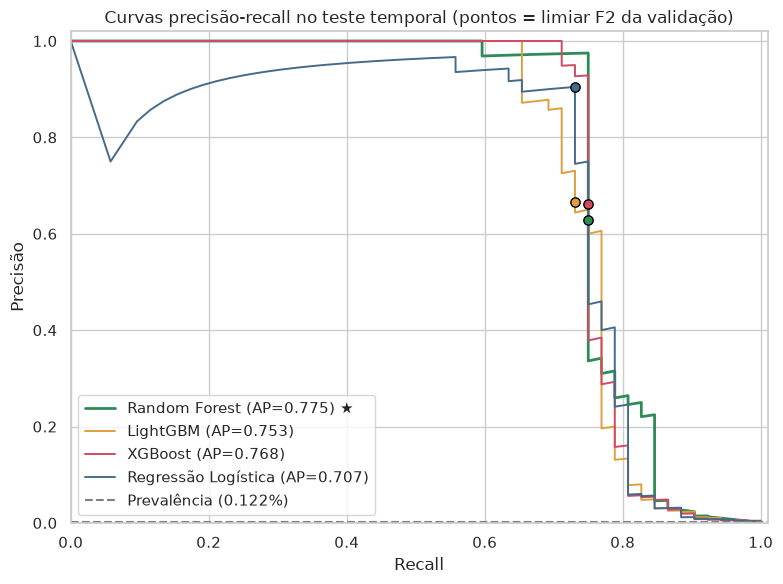

In [7]:
# Curvas precisão-recall dos quatro modelos no teste, no mesmo gráfico.
cores = {"Regressão Logística": "#466B8A", "Random Forest": "#2E8B57", "XGBoost": "#D14A61", "LightGBM": "#E09F3E"}
fig, ax = plt.subplots(figsize=(8, 6))
for nome in selecao.index:
    p, r, _ = precision_recall_curve(yt, prob_teste[nome])
    ap = average_precision_score(yt, prob_teste[nome])
    ax.plot(r, p, color=cores[nome], lw=2 if nome == vencedor else 1.4,
            label=f"{nome} (AP={ap:.3f})" + (" ★" if nome == vencedor else ""))
    # Ponto no limiar F2 escolhido na validação.
    linha = principal.set_index("Modelo").loc[nome]
    ax.scatter(linha["Recall"], linha["Precisão"], color=cores[nome], edgecolor="black", zorder=3, s=45)
ax.axhline(yt.mean(), color="gray", linestyle="--", label=f"Prevalência ({yt.mean():.3%})")
ax.set(xlabel="Recall", ylabel="Precisão", xlim=(0, 1.01), ylim=(0, 1.02),
       title="Curvas precisão-recall no teste temporal (pontos = limiar F2 da validação)")
ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig(PASTA_RELATORIOS / "pr_curves.png", bbox_inches="tight"); plt.show()

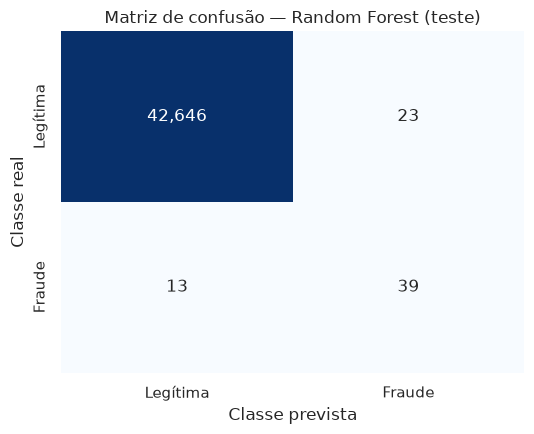

Random Forest: 39 de 52 fraudes detectadas, 23 alertas falsos, 1.45 alertas por 1.000 transações.


In [8]:
# Matriz de confusão do vencedor no teste (limiar F2).
linha = principal.set_index("Modelo").loc[vencedor]
matriz = np.array([[linha["VN"], linha["FP"]], [linha["FN"], linha["VP"]]])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz, annot=True, fmt=",", cmap="Blues", cbar=False,
            xticklabels=["Legítima", "Fraude"], yticklabels=["Legítima", "Fraude"], ax=ax)
ax.set(xlabel="Classe prevista", ylabel="Classe real", title=f"Matriz de confusão — {vencedor} (teste)")
fig.tight_layout(); fig.savefig(PASTA_RELATORIOS / "confusao_vencedor.png", bbox_inches="tight"); plt.show()
print(f"{vencedor}: {linha['VP']} de {linha['VP'] + linha['FN']} fraudes detectadas, "
      f"{linha['FP']} alertas falsos, {linha['Alertas por 1.000']:.2f} alertas por 1.000 transações.")

### Incerteza: bootstrap da AP no teste

Com apenas 52 fraudes no teste, uma única fraude a mais ou a menos muda o recall em ~0,02. Para medir essa incerteza, reamostro o teste com reposição (1.000 vezes, estratificado por classe) e recalculo a AP de cada modelo e a diferença pareada em relação ao vencedor.

In [9]:
rng = np.random.default_rng(SEED)
idx_pos, idx_neg = np.where(yt.to_numpy() == 1)[0], np.where(yt.to_numpy() == 0)[0]
y_arr = yt.to_numpy()
amostras = {n: [] for n in selecao.index}
for _ in range(1000):
    idx = np.concatenate([rng.choice(idx_pos, len(idx_pos)), rng.choice(idx_neg, len(idx_neg))])
    for n in selecao.index:
        amostras[n].append(average_precision_score(y_arr[idx], prob_teste[n][idx]))
amostras = pd.DataFrame(amostras)
dif = amostras.sub(amostras[vencedor], axis=0)
incerteza = pd.DataFrame({
    "AP teste": [average_precision_score(yt, prob_teste[n]) for n in selecao.index],
    "IC95% inferior": amostras.quantile(0.025), "IC95% superior": amostras.quantile(0.975),
    f"Δ AP vs {vencedor} (mediana)": dif.median(),
    f"P(modelo > {vencedor})": (dif > 0).mean(),
}, index=selecao.index)
incerteza.round(3).to_csv(PASTA_RELATORIOS / "bootstrap_ap_teste.csv")
display(incerteza.round(3))

,AP teste,IC95% inferior,IC95% superior,Δ AP vs Random Forest (mediana),P(modelo > Random Forest)
Random Forest,0.775,0.672,0.882,0.000,0.000
LightGBM,0.753,0.643,0.863,-0.021,0.161
XGBoost,0.768,0.662,0.880,-0.007,0.209
Regressão Logística,0.707,0.583,0.854,-0.062,0.070


## 6. Conclusão

A análise escrita dos resultados está na seção **"Comparação de modelos"** do [`README.md`](README.md). Limitações principais: uma única partição temporal (~48 h, 52 fraudes no teste, portanto alta variância), variáveis `V1`–`V28` anonimizadas por PCA e `Time` usado como variável de entrada (mantido para comparabilidade com o projeto original, embora um modelo de árvore não extrapole bem valores de `Time` fora do intervalo do treino).